# Word Vectors and Job Categories - Solution

**Business problem:** suggest one of four categories for a publisher to review.

A model supports a decision; it does not make the business decision for us.

Start with the [spam worked example in the concept notebook](text_embeddings_concept.ipynb). Here we transfer its text → word vectors → document mean → classifier workflow to job categories. Unlike the spam example's invented vectors, this exercise learns word2vec from training text.

## Learning objectives

- Compare a text representation with frequency and TF-IDF baselines.
- Keep fitting, validation selection and final evaluation separate.
- Interpret errors and limits before proposing a business use.

## Dataset and practical scope

120 original synthetic German ads: 72 train, 24 validation, 24 test, ordered by constructed date. IDs and dates are not model features. Shared simple templates make this easier than a real job market. The measured results here do not reproduce the real-data slides.

All code is supplied. Run the cells from top to bottom.

## Libraries and settings

Use the prepared Python 3.11 Codespace kernel. No GPU or API key is needed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 7
np.random.seed(SEED)
DATA_ROOT = Path('../../../00_Data')

## 1. Minimal data inspection

Read the supplied CSV and retain its fixed chronological partitions.

In [9]:
jobs = pd.read_csv(DATA_ROOT / 'nlp_teaching_jobs.csv', parse_dates=['creation_date'])
parts = {name: jobs[jobs['split'] == name].copy()
         for name in ['train', 'validation', 'test']}
display(jobs[['text', 'category', 'split']].head())
display(jobs.groupby(['split', 'category']).size().unstack())

,text,category,split
0,Du betreibst ETL-Prozesse. Du arbeitest mit Ai...,Data engineering,train
1,Du entwickelst Webanwendungen. Du arbeitest mi...,Software development,train
2,Du bearbeitest Reklamationen. Du arbeitest mit...,Customer service,train
3,Du prüfst Rechnungen. Du arbeitest mit Excel u...,Accounting,train
4,Du prüfst die Qualität unserer Analysedaten. D...,Data engineering,train


category,Accounting,Customer service,Data engineering,Software development
split,,,,
test,6,6,6,6
train,18,18,18,18
validation,6,6,6,6


## 2. Business and statistical baseline

A frequency baseline ignores text. TF-IDF plus logistic regression is a stronger lexical baseline. Fit vocabulary and IDF on training ads only.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train = parts['train']['category']
y_validation = parts['validation']['category']
y_test = parts['test']['category']
prior = DummyClassifier(strategy='prior').fit(np.zeros((len(y_train), 1)), y_train)
tfidf = TfidfVectorizer(ngram_range=(1, 2))
lexical = {name: tfidf.fit_transform(frame['text']) if name == 'train'
           else tfidf.transform(frame['text']) for name, frame in parts.items()}

## 3. Learn word vectors from training text

The supplied small skip-gram network predicts nearby words with full softmax, as in the lecture. The class labels are not used for word-vector learning. A batch contains centre/neighbor pairs; an epoch visits all pairs. This tiny corpus cannot establish general semantic understanding.

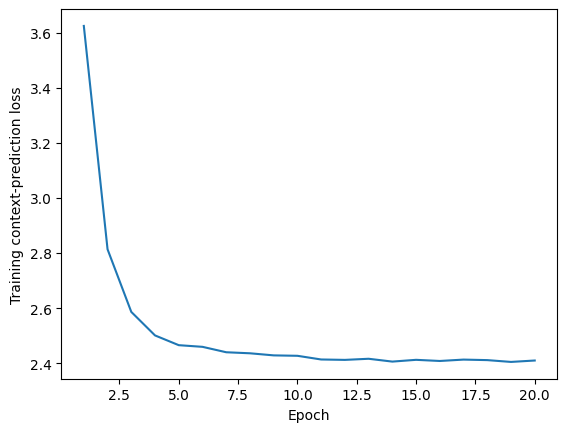

In [15]:
import re                                      # Importiert Funktionen für reguläre Ausdrücke.
import torch                                   # Importiert PyTorch.
from torch import nn                           # Importiert Bausteine für neuronale Netze.

torch.manual_seed(SEED)                        # Setzt den Zufalls-Seed für reproduzierbare Ergebnisse.
torch.set_num_threads(2)                       # Beschränkt PyTorch auf zwei CPU-Threads.

tokens = [re.findall(r"[^\W\d_]+", text.lower())  # Extrahiert Wörter aus jedem Text und wandelt sie in Kleinbuchstaben um.
          for text in parts['train']['text']]     # Führt dies für alle Trainings-Texte aus.

vocabulary = sorted({word for sentence in tokens  # Erstellt ein sortiertes Vokabular.
                     for word in sentence})       # Nimmt jedes unterschiedliche Wort nur einmal auf.

word_id = {word: i for i, word in enumerate(vocabulary)}  # Ordnet jedem Wort eine eindeutige ID zu.

pairs = []                                       # Erstellt eine leere Liste für Wort-Kontext-Paare.

for sentence in tokens:                          # Durchläuft alle tokenisierten Texte.
    ids = [word_id[word] for word in sentence]   # Ersetzt jedes Wort durch seine ID.

    for centre, word in enumerate(ids):          # Durchläuft jedes Wort und dessen Position.
        for neighbour in range(                   # Durchläuft die Positionen im Kontextfenster.
            max(0, centre - 2),                    # Berücksichtigt höchstens zwei Wörter links.
            min(len(ids), centre + 3)              # Berücksichtigt höchstens zwei Wörter rechts.
        ):
            if neighbour != centre:              # Überspringt das Mittelpunktwort selbst.
                pairs.append(                     # Fügt ein Trainingspaar hinzu.
                    (word, ids[neighbour])       # Mittelpunktwort und benachbartes Kontextwort.
                )

pairs = torch.tensor(pairs, dtype=torch.long)   # Wandelt die Paare in einen PyTorch-Tensor um.


class SkipGram(nn.Module):                       # Definiert das Skip-Gram-Modell.
    def __init__(self, size, dimensions=24):     # Initialisiert das Modell.
        super().__init__()                       # Initialisiert die Basisklasse von PyTorch.
        self.words = nn.Embedding(               # Erstellt die Wort-Embedding-Schicht.
            size, dimensions                     # Ein Vektor pro Wort mit 24 Dimensionen.
        )
        self.context = nn.Linear(                # Erstellt die Ausgabeschicht.
            dimensions, size, bias=False         # Berechnet Scores für alle Wörter im Vokabular.
        )

    def forward(self, centres):                  # Definiert den Vorwärtsdurchlauf.
        return self.context(                     # Berechnet Vorhersagen für Kontextwörter.
            self.words(centres)                 # Wandelt Wort-IDs in Embedding-Vektoren um.
        )


word_model = SkipGram(len(vocabulary))           # Erstellt das Modell mit der Größe des Vokabulars.
optimizer = torch.optim.Adam(                    # Erstellt den Adam-Optimierer.
    word_model.parameters(), lr=0.02             # Optimiert alle Modellparameter mit Lernrate 0,02.
)
loss_function = nn.CrossEntropyLoss()            # Legt die Verlustfunktion für Klassifikation fest.
losses = []                                      # Speichert den Verlust jeder Epoche.

for epoch in range(20):                          # Trainiert das Modell 20 Epochen lang.
    order = torch.randperm(len(pairs))           # Erstellt eine zufällige Reihenfolge der Trainingspaare.
    batch_losses = []                            # Speichert die Verluste der einzelnen Batches.

    for batch in order.split(128):               # Teilt die Daten in Batches mit maximal 128 Paaren.
        centres, neighbours = pairs[batch].T    # Trennt Mittelpunkt- und Kontextwort-IDs.
        optimizer.zero_grad()                   # Setzt die alten Gradienten zurück.
        loss = loss_function(                   # Berechnet den aktuellen Trainingsverlust.
            word_model(centres), neighbours     # Vergleicht Modellvorhersagen mit den echten Kontextwörtern.
        )
        loss.backward()                          # Berechnet die Gradienten.
        optimizer.step()                         # Aktualisiert die Modellparameter.
        batch_losses.append(loss.item())         # Speichert den Verlust des aktuellen Batches.

    losses.append(np.mean(batch_losses))         # Speichert den durchschnittlichen Epochenverlust.


plt.plot(range(1, 21), losses)                   # Zeichnet den Verlustverlauf der 20 Epochen.
plt.xlabel('Epoch')                              # Beschriftet die x-Achse.
plt.ylabel('Training context-prediction loss')  # Beschriftet die y-Achse.
plt.show()                                       # Zeigt das Diagramm an.

lookup = word_model.words.weight.detach().numpy()  # Extrahiert die trainierten Wort-Embeddings als NumPy-Array.

## 4. Average known word vectors

**Coding task:** compute the coordinate-wise mean of `known` using NumPy and `axis=0`. The supplied function skips unknown words but explicitly reports an entirely unrepresented text.

In [16]:
def document_mean(text):
    words = re.findall(r"[^\W\d_]+", text.lower())
    known = [lookup[word_id[word]] for word in words if word in word_id]
    if not known:
        raise ValueError('This text contains no known words; it needs another representation or review.')
    mean = np.mean(known, axis=0)
    return mean

vectors = {name: np.vstack([document_mean(text) for text in frame['text']])
           for name, frame in parts.items()}
print('Training vector matrix:', vectors['train'].shape)

Training vector matrix: (72, 24)


### Interpret the result

Can falling context-prediction loss establish better category decisions?

**Suggested answer:** No. That loss predicts neighboring words. Category decisions require a separate classifier and validation/test evidence.

**Self-check:** Distinguish the two targets and identify the appropriate evaluation data.

**Difficulty:** moderate. A common mistake is treating a model score as business value.

## 5. Train and select the category classifier

**Coding task:** create `LogisticRegression(C=regularization, max_iter=600, random_state=SEED)`. The supplied loop compares C=0.3 and C=1 using validation macro-F1, giving each category equal weight. Choose the smaller C on a tie. Scaling is fitted on training vectors only.

In [17]:
representations = {'TF-IDF': lexical, 'word2vec': vectors}  # Speichert beide Textrepräsentationen.
chosen = {}  # Speichert später das jeweils beste Modell.
validation_rows = []  # Sammelt die Validierungsergebnisse.

for name, matrices in representations.items():  # Durchläuft TF-IDF und Word2Vec.
    candidates = []  # Speichert die getesteten Modelle.
    for regularization in [0.3, 1.0]:  # Testet zwei Regularisierungswerte.
        classifier = LogisticRegression(C=regularization, max_iter=600, random_state=SEED)  # Erstellt einen Klassifikator.
        model = (make_pipeline(StandardScaler(), classifier)  # Standardisiert Word2Vec-Daten vor der Klassifikation.
                 if name == 'word2vec' else classifier)  # Verwendet für TF-IDF nur den Klassifikator.
        model.fit(matrices['train'], y_train)  # Trainiert das Modell mit den Trainingsdaten.
        score = f1_score(y_validation, model.predict(matrices['validation']), average='macro')  # Berechnet den Macro-F1-Score.
        candidates.append((score, regularization, model))  # Speichert Score, C-Wert und Modell.
        validation_rows.append({'model': name, 'C': regularization, 'validation macro-F1': score})  # Speichert das Ergebnis tabellarisch.
    candidates.sort(key=lambda item: (-item[0], item[1]))  # Sortiert nach bestem Score und anschließend kleinstem C-Wert.
    chosen[name] = candidates[0][2]  # Speichert das beste Modell der jeweiligen Repräsentation.

display(pd.DataFrame(validation_rows))  # Zeigt alle Validierungsergebnisse als Tabelle an.

,model,C,validation macro-F1
0,TF-IDF,0.3,1.000000
1,TF-IDF,1.0,1.000000
2,word2vec,0.3,0.918831
3,word2vec,1.0,0.918831


## 6. Evaluate fixed choices

Do not change settings after seeing these test results. Accuracy counts correct first labels; macro-F1 weights categories equally.

In [7]:
test_predictions = {'Frequency': prior.predict(np.zeros((len(y_test), 1)))}
for name, model in chosen.items():
    test_predictions[name] = model.predict(representations[name]['test'])
results = [{'model': name,
            'accuracy': accuracy_score(y_test, prediction),
            'macro-F1': f1_score(y_test, prediction, average='macro')}
           for name, prediction in test_predictions.items()]
display(pd.DataFrame(results).set_index('model').round(3))

,accuracy,macro-F1
model,,
Frequency,0.250,0.100
TF-IDF,1.000,1.000
word2vec,0.958,0.958


### Interpret the result

Which recipe would you investigate further? What prevents a deployment claim?

**Suggested answer:** In the saved run, TF-IDF classifies all test ads correctly, while word2vec gets about 96% right. Learned word vectors have not improved this task. Start with the simple baseline, but validate on real writing styles and meaningful publisher outcomes. Shared synthetic templates make these scores unusually high; they do not establish deployment performance or a universal ranking.

**Self-check:** Cite actual metrics, one failure mode and one business outcome to evaluate.

**Difficulty:** moderate. A common mistake is treating a model score as business value.

## Interpretation: inspect individual decisions

A confusion matrix and a few predictions help identify errors; do not interpret estimated category probabilities as calibrated truth.

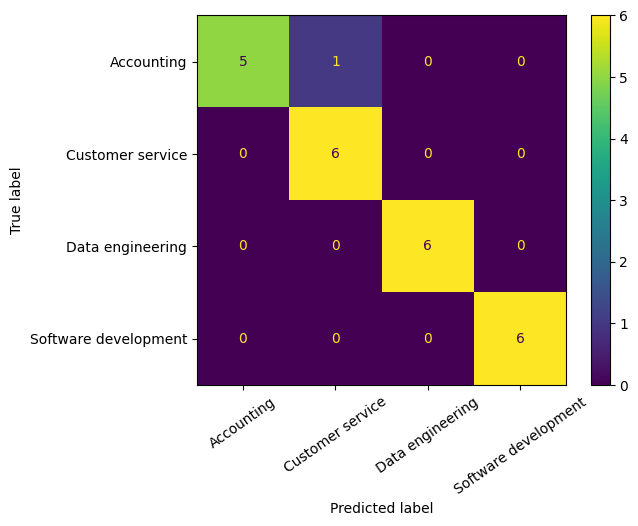

,text,category,predicted
96,Du bindest neue Datenquellen an. Du arbeitest ...,Data engineering,Data engineering
97,Du entwickelst Webanwendungen. Du arbeitest mi...,Software development,Software development
98,Du berätst unsere Kunden. Du arbeitest mit Ges...,Customer service,Customer service
99,Du bearbeitest Kreditoren und Debitoren. Du ar...,Accounting,Accounting
100,Du betreibst ETL-Prozesse. Du arbeitest mit Bi...,Data engineering,Data engineering
101,Du testest unsere Software. Du arbeitest mit C...,Software development,Software development


In [8]:
prediction = test_predictions['word2vec']
ConfusionMatrixDisplay.from_predictions(y_test, prediction, xticks_rotation=35)
plt.show()
display(parts['test'][['text', 'category']].assign(predicted=prediction).head(6))

## Summary and business implications

Select with validation evidence, evaluate fixed recipes, then connect errors to publisher review. Changing representations is not a controlled causal experiment.

## Limitations

This is a small teaching example, not evidence of deployment performance. Keep evaluation separate from fitting and model selection. Check errors and the user's decision, not only a headline metric.

## Further exercises

- Inspect mistakes rather than only the mean score.
- What happens to unknown words or truncated requirements?
- Optional: use an authorized real dataset with a documented chronological split; do not redistribute private text.

## References

**Required reading:** Stanford CS224N, Spring 2024, word-vector lecture, supplied excerpt.
**Instructor reference:** Mikolov et al. (2013), *Efficient Estimation of Word Representations in Vector Space*.
https://arxiv.org/abs/1301.3781
**Official documentation:** https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction

### Jupyter notebook - footer info

Include your name, submission date and a short description of your changes when submitting.